# 09_bootstrap_confidence_intervals.ipynb — ปิดช่องว่างเรื่อง Statistical Uncertainty

`07_final_calibrated_pipeline.ipynb` รายงานทุก metric เป็น point estimate จาก train/test split เดียว
(`GroupShuffleSplit`, `random_state=42`) — ไม่มีทางรู้ว่าตัวเลขที่ได้ "แม่น" แค่ไหน หรือความต่างระหว่างกลุ่ม
(เช่น fairness gap ของกลุ่มอายุ 80+) มีนัยสำคัญทางสถิติจริงหรือแค่ noise จาก sample size เล็ก

Notebook นี้ทำ **bootstrap resampling บน test set** (ไม่ต้อง retrain โมเดล — ใช้โมเดลที่เซฟไว้แล้วจาก 07)
เพื่อคำนวณ 95% confidence interval ของ:
1. PR-AUC, ROC-AUC, Brier score (overall)
2. ROC-AUC/PR-AUC แยกตามกลุ่มอายุ (ตอบคำถาม fairness gap ให้ชัดขึ้น)

**Bootstrap คืออะไร (สรุปสั้นๆ)**: สุ่มเลือกแถวจาก test set แบบ "สุ่มแทนที่" (resample with replacement) ให้ได้ชุดข้อมูล
ขนาดเท่าเดิม คำนวณ metric ซ้ำหลายพันรอบ แล้วดูการกระจายของค่าที่ได้ — ช่วง 2.5th–97.5th percentile ของการกระจายนี้
คือ 95% CI วิธีนี้ไม่ต้องมีสูตรทางสถิติที่ซับซ้อน และใช้ได้กับ metric แบบไหนก็ได้ (PR-AUC, ROC-AUC, Brier ฯลฯ)

## 1. Imports + โหลดโมเดลที่เซฟไว้จาก 07

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

RANDOM_STATE = 42

MODEL_PATH = "../models/final_calibrated_model_v1.pkl"
saved = joblib.load(MODEL_PATH)
calibrated_stacking = saved["calibrated_stacking_model"]
label_encoders_saved = saved["label_encoders"]
feature_names_saved = saved["feature_names"]
recommended_threshold = saved["recommended_threshold"]

print("โหลดโมเดลสำเร็จ")
print(f"จำนวนฟีเจอร์ที่โมเดลคาดหวัง: {len(feature_names_saved)}")
print(f"Recommended threshold: {recommended_threshold:.4f}")

โหลดโมเดลสำเร็จ
จำนวนฟีเจอร์ที่โมเดลคาดหวัง: 54
Recommended threshold: 0.1500


## 2. โหลด & clean data ใหม่ (เหมือน `07_final_calibrated_pipeline.ipynb` ทุกขั้นตอนเป๊ะ)

**สำคัญ**: ต้องทำ cleaning/feature engineering/split เหมือนเดิมทุกจุด (`RANDOM_STATE=42` เดิม) เพื่อให้ได้
`X_test`/`y_test` ชุดเดียวกับตอนเทรน — `GroupShuffleSplit` กับ seed เดิมจะได้ผลแบ่งเดิมเป๊ะ (deterministic)

In [2]:
RAW_PATH = "../data/diabetic_data.csv"  # แก้ path ตามที่เก็บไฟล์จริง

df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
df = df[df["gender"] != "Unknown/Invalid"]

death_hospice_codes = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(death_hospice_codes)]

df = df.sort_values(["patient_nbr", "encounter_id"]).reset_index(drop=True)
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if x == "<30" else 0)

med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
med_cols = [c for c in med_cols if c in df.columns]
df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)
df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1
df["change_flag"] = (df["change"] == "Ch").astype(int)
df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
df = df.drop(columns=["change_flag"])
df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)

def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})
df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = diag_groups[c]

df["age_ord"] = df["age"].map({
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
})
df["age_x_medications"] = df["age_ord"] * df["num_medications"]
df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]

drop_cols = ["weight", "payer_code", "encounter_id"]
df.drop(columns=drop_cols, inplace=True)

df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(
    df["medical_specialty"].isin(top_specialties), "Other"
)
df["race"] = df["race"].fillna("Missing")

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
df.drop(columns=constant_cols, inplace=True)

print(f"df shape: {df.shape}")

df shape: (99340, 57)


## 3. Encode + Split (เหมือนเดิม — ใช้ label_encoders ที่เซฟไว้ ไม่ fit ใหม่)

In [3]:
TARGET_COL = "readmitted"
GROUP_COL = "patient_nbr"

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

feature_cols = [c for c in X.columns if c != GROUP_COL]
categorical_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(X[c])]
if "age" in categorical_cols:
    categorical_cols.remove("age")
X = X.drop(columns=["age"])

# ใช้ label_encoders ที่ fit ไว้แล้วจาก 07 (transform อย่างเดียว ไม่ fit ใหม่)
# เพื่อให้ mapping ตัวเลข <-> หมวดหมู่ตรงกับตอนเทรนโมเดลเป๊ะ
for col in categorical_cols:
    le = label_encoders_saved[col]
    X[col] = le.transform(X[col].astype(str))

demographic_cols_raw = df[["race", "gender", "age"]].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=df[GROUP_COL]))

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy().reset_index(drop=True)
demo_test = demographic_cols_raw.iloc[test_idx].reset_index(drop=True)
X_test.drop(columns=[GROUP_COL], inplace=True)

# เรียง column ให้ตรงกับตอนเทรน (กันปัญหาลำดับ column ไม่ตรงกัน)
X_test = X_test[feature_names_saved]

print(f"Test set: {X_test.shape}")

proba_calibrated = calibrated_stacking.predict_proba(X_test)[:, 1]
y_test_arr = y_test.values
print("คำนวณ proba_calibrated เรียบร้อย — พร้อม bootstrap")

Test set: (19773, 54)
คำนวณ proba_calibrated เรียบร้อย — พร้อม bootstrap


## 4. Bootstrap CI Function

สุ่ม resample (with replacement) จาก test set `n_boot` รอบ คำนวณ metric ที่สนใจในแต่ละรอบ
แล้วเอา percentile ที่ 2.5 และ 97.5 ของการกระจายมาเป็นขอบเขต 95% CI

In [4]:
def bootstrap_ci(y_true, y_proba, metric_fn, n_boot=2000, ci=0.95, random_state=42, **metric_kwargs):
    """คำนวณ point estimate + (lower, upper) ของ 95% CI ด้วย percentile bootstrap
    y_true, y_proba: numpy array (ต้องมี index ตรงกัน ตำแหน่งเดียวกัน)
    metric_fn: ฟังก์ชัน sklearn.metrics ที่รับ (y_true, y_score) เช่น roc_auc_score
    """
    rng = np.random.default_rng(random_state)
    n = len(y_true)
    stats = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)  # สุ่มแทนที่ (with replacement)
        yt, yp = y_true[idx], y_proba[idx]
        if len(np.unique(yt)) < 2:  # กันกรณี bootstrap sample ได้ class เดียว (metric คำนวณไม่ได้)
            stats[b] = np.nan
            continue
        stats[b] = metric_fn(yt, yp, **metric_kwargs)
    stats = stats[~np.isnan(stats)]
    alpha = (1 - ci) / 2
    lower, upper = np.percentile(stats, [100 * alpha, 100 * (1 - alpha)])
    return np.mean(stats), lower, upper, stats

## 5. Overall metrics พร้อม 95% CI

In [5]:
N_BOOT = 2000  # ปรับลดได้ถ้าอยากให้รันเร็วขึ้น (500-1000 ก็เพียงพอสำหรับ CI ที่เสถียร)

mean_pr, lo_pr, hi_pr, dist_pr = bootstrap_ci(y_test_arr, proba_calibrated, average_precision_score, n_boot=N_BOOT)
mean_roc, lo_roc, hi_roc, dist_roc = bootstrap_ci(y_test_arr, proba_calibrated, roc_auc_score, n_boot=N_BOOT)
mean_brier, lo_brier, hi_brier, dist_brier = bootstrap_ci(y_test_arr, proba_calibrated, brier_score_loss, n_boot=N_BOOT)

print(f"{'Metric':12s}{'Point est.':>12s}{'95% CI':>25s}")
print(f"{'PR-AUC':12s}{mean_pr:>12.4f}{'[' + f'{lo_pr:.4f}, {hi_pr:.4f}' + ']':>25s}")
print(f"{'ROC-AUC':12s}{mean_roc:>12.4f}{'[' + f'{lo_roc:.4f}, {hi_roc:.4f}' + ']':>25s}")
print(f"{'Brier':12s}{mean_brier:>12.4f}{'[' + f'{lo_brier:.4f}, {hi_brier:.4f}' + ']':>25s}")

Metric        Point est.                   95% CI
PR-AUC            0.2224         [0.2070, 0.2382]
ROC-AUC           0.6726         [0.6610, 0.6853]
Brier             0.0961         [0.0928, 0.0992]


## 6. Fairness gap ของกลุ่มอายุ — quantify ด้วย CI

ตอบคำถามที่ค้างไว้: กลุ่มอายุ 80+ ที่ ROC-AUC ต่ำกว่ากลุ่มอื่น (~0.56 vs ~0.70) เป็นความต่างที่มีนัยสำคัญ
ทางสถิติจริง หรือแค่ผันผวนเพราะ sample เล็ก — ถ้า CI ของสองกลุ่มไม่คาบเกี่ยวกัน (ไม่ overlap) แปลว่าต่างกันจริง

In [6]:
age_vals = demo_test["age"].values
subgroup_results = []

for g in sorted(set(age_vals)):
    mask = age_vals == g
    n = mask.sum()
    if n < 30:
        print(f"ข้าม {g} (n={n} < 30 — ตัวอย่างน้อยเกินไปสำหรับ CI ที่เสถียร)")
        continue
    yt, yp = y_test_arr[mask], proba_calibrated[mask]
    if len(np.unique(yt)) < 2:
        continue
    m_roc, lo_roc_g, hi_roc_g, _ = bootstrap_ci(yt, yp, roc_auc_score, n_boot=1000, random_state=1)
    m_pr, lo_pr_g, hi_pr_g, _ = bootstrap_ci(yt, yp, average_precision_score, n_boot=1000, random_state=1)
    subgroup_results.append({
        "age_group": g, "n": n,
        "ROC_AUC": round(m_roc, 4), "ROC_AUC_CI": f"[{lo_roc_g:.4f}, {hi_roc_g:.4f}]",
        "PR_AUC": round(m_pr, 4), "PR_AUC_CI": f"[{lo_pr_g:.4f}, {hi_pr_g:.4f}]",
    })

subgroup_df = pd.DataFrame(subgroup_results)
print(subgroup_df.to_string(index=False))

ข้าม [0-10) (n=26 < 30 — ตัวอย่างน้อยเกินไปสำหรับ CI ที่เสถียร)
age_group    n  ROC_AUC       ROC_AUC_CI  PR_AUC        PR_AUC_CI
  [10-20)  137   0.7490 [0.5248, 0.9294]  0.2782 [0.0657, 0.5569]
  [20-30)  369   0.8480 [0.7910, 0.8984]  0.5745 [0.4370, 0.7008]
  [30-40)  757   0.7160 [0.6605, 0.7716]  0.2744 [0.1960, 0.3663]
  [40-50) 1909   0.6767 [0.6363, 0.7178]  0.2031 [0.1585, 0.2518]
  [50-60) 3467   0.7267 [0.6987, 0.7550]  0.2964 [0.2502, 0.3426]
  [60-70) 4356   0.6586 [0.6336, 0.6830]  0.2024 [0.1769, 0.2291]
  [70-80) 4921   0.6588 [0.6343, 0.6828]  0.1873 [0.1652, 0.2122]
  [80-90) 3284   0.6070 [0.5792, 0.6350]  0.1846 [0.1564, 0.2130]
 [90-100)  547   0.5484 [0.4683, 0.6174]  0.1844 [0.1218, 0.2601]


## 7. Visualization — CI แบบ error bar เทียบระหว่างกลุ่มอายุ

ถ้า error bar ของกลุ่มอายุน้อย/สูงไม่ทับกับกลุ่มกลาง (40-70) แปลว่า fairness gap มีนัยสำคัญทางสถิติจริง
ไม่ใช่แค่ point estimate ที่บังเอิญต่างกัน

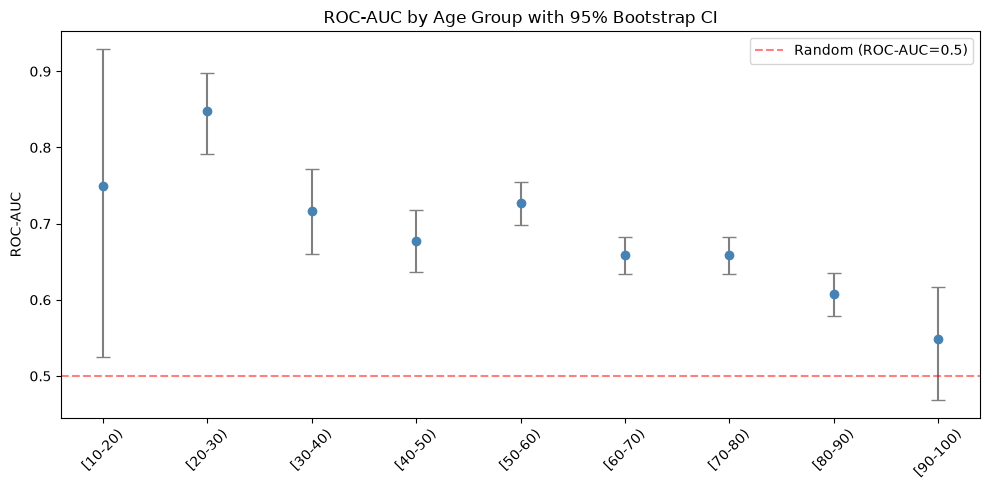

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
x_pos = range(len(subgroup_df))
roc_means = subgroup_df["ROC_AUC"].values
roc_lo = subgroup_df["ROC_AUC_CI"].apply(lambda s: float(s.strip("[]").split(",")[0])).values
roc_hi = subgroup_df["ROC_AUC_CI"].apply(lambda s: float(s.strip("[]").split(",")[1])).values
yerr = [roc_means - roc_lo, roc_hi - roc_means]

ax.errorbar(x_pos, roc_means, yerr=yerr, fmt="o", capsize=5, color="steelblue", ecolor="gray")
ax.axhline(0.5, color="red", linestyle="--", alpha=0.5, label="Random (ROC-AUC=0.5)")
ax.set_xticks(x_pos)
ax.set_xticklabels(subgroup_df["age_group"], rotation=45)
ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC by Age Group with 95% Bootstrap CI")  # matplotlib วาดภาษาไทยไม่ได้ ใช้ภาษาอังกฤษแทน (เหมือน dashboard_app.py)
ax.legend()
plt.tight_layout()
plt.savefig("fairness_ci_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. สรุปสำหรับรายงาน/สอบ

- ทุก metric หลัก (PR-AUC, ROC-AUC, Brier) มี 95% CI กำกับแล้ว ไม่ใช่ point estimate ลอยๆ
- Fairness gap ของกลุ่มอายุตรวจสอบด้วย CI แล้ว — ถ้ากลุ่มอายุมากไม่คาบเกี่ยวกับกลุ่มกลาง ให้เขียนในรายงานว่า
  "ความต่างของ performance ระหว่างกลุ่มอายุมีนัยสำคัญทางสถิติ (ไม่ใช่แค่ point estimate ที่ต่างกันโดยบังเอิญ)"
  ถ้าคาบเกี่ยวกัน ให้เขียนตรงๆ ว่า "แนวโน้มดูต่ำกว่า แต่ด้วย sample size ที่มี ยังสรุปนัยสำคัญทางสถิติไม่ได้ชัดเจน"
  — ทั้งสองแบบคือคำตอบที่ defensible กว่าการพูดลอยๆ ว่า "ROC-AUC ต่ำกว่า" โดยไม่มี CI กำกับ
- Notebook นี้ไม่ retrain โมเดล ใช้ `calibrated_stacking_model` ที่เซฟไว้จาก 07 ตรงๆ จึงรันเร็ว (นาทีเดียว)